In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse

root = Path("Data")
meta = pd.read_csv(root / "metadata.csv")

#load H3K27ac
data_H3K27ac = sparse.load_npz(root / "H3K27ac" / "counts.npz") 
bins_ac = np.load(root / "H3K27ac" / "bins.npz")
chrom_ac = bins_ac["chrom_levels"][bins_ac["chrom_codes"]]
start_ac, end_ac = bins_ac["start"], bins_ac["end"]

#load H3K27me3
data_H3K27me3 = sparse.load_npz(root / "H3K27me3" / "counts.npz")
bins_me3 = np.load(root / "H3K27me3" / "bins.npz")
chrom_me3 = bins_me3["chrom_levels"][bins_me3["chrom_codes"]]
start_me3, end_me3 = bins_me3["start"], bins_me3["end"]

#extract the label of the cells
y = meta["cell_type"].to_numpy()

In [7]:
#shape of the data (H3K27ac, H3K27me3, cell types)
print(f'Shape H3K27ac : {data_H3K27ac.shape}, shape H3K27me3 : {data_H3K27me3.shape}, shape cell types : {len(y)}') #only the non-zero values

Shape H3K27ac : (4805, 3782654), shape H3K27me3 : (4805, 2350516), shape cell types : 4805


In [10]:
#Overview of the bins (start, end, chromosome) for each histone mark
print('H3K27ac :')
print(f' - Starting of each bin: {start_ac[0:10]} \n - Ending: {end_ac[0:10]} \n - Chromosome: {chrom_ac[0:10]}')
print('H3K27me3 :')
print(f' - Starting of each bin: {start_me3[0:10]} \n - Ending: {end_me3[0:10]} \n - Chromosome: {chrom_me3[0:10]}')

H3K27ac :
 - Starting of each bin: [3003500 3006500 3007000 3008000 3009000 3010000 3011500 3012500 3013000
 3014500] 
 - Ending: [3004000 3007000 3007500 3008500 3009500 3010500 3012000 3013000 3013500
 3015000] 
 - Chromosome: ['chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1']
H3K27me3 :
 - Starting of each bin: [3005000 3005500 3011500 3021500 3028000 3028500 3033000 3033500 3048000
 3048500] 
 - Ending: [3005500 3006000 3012000 3022000 3028500 3029000 3033500 3034000 3048500
 3049000] 
 - Chromosome: ['chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1']


# 1. Prevalence filter

In [16]:
#filter out the bins that have non-zero values in more than 50 cells

#H3K27ac
count_col_ac = data_H3K27ac.getnnz(axis=0)
keep_ac = count_col_ac >= 50
print(f'Number of bins with more than 50 non-zero values in H3K27ac: {keep_ac.sum()}')

#H3K27me3
count_col_me3 = data_H3K27me3.getnnz(axis=0)
keep_me3 = count_col_me3 >= 50
print(f'Number of bins with more than 50 non-zero values in H3K27me3: {keep_me3.sum()}')

Number of bins with more than 50 non-zero values in H3K27ac: 43970
Number of bins with more than 50 non-zero values in H3K27me3: 10878


In [17]:
#Keep only the bins that have more than 50 non-zero values

#H3K27ac
H3K27ac_filter = data_H3K27ac[:, keep_ac]
chrom_H3K27ac_filter = chrom_ac[keep_ac]
start_H3K27ac_filter = start_ac[keep_ac]
end_H3K27ac_filter = end_ac[keep_ac]

#H3K27me3
H3K27me3_filter = data_H3K27me3[:, keep_me3]
chrom_H3K27me3_filter = chrom_me3[keep_me3]
start_H3K27me3_filter = start_me3[keep_me3]
end_H3K27me3_filter = end_me3[keep_me3]

print(f'Shape H3K27ac after filtering: {H3K27ac_filter.shape}, shape H3K27me3 after filtering: {H3K27me3_filter.shape}')

Shape H3K27ac after filtering: (4805, 43970), shape H3K27me3 after filtering: (4805, 10878)


### Increasing bins size (to much bins have not much non zero values, and decrease number of features)

In [18]:
#Increase size of the bins to a factor x

def increase_bins(data, chrom, start, end, factor, size=500) :
    
    chrom = np.asarray(chrom)
    start = np.asarray(start)
    end = np.asarray(end)
    n = len(start)
    width = size * factor #max size of the new bins
    
    group = np.zeros(n, dtype=np.int64) #where each bin belongs to a group of bins that will be merged together
    new_start = [start[0]]
    new_end = [end[0]]
    new_chrom = [chrom[0]]
    g = 0 #counter for the group number
    
    for i in range(1, n) :
        if chrom[i] == new_chrom[-1] and start[i] < new_start[-1] + width : #if the bin is on the same chromosome and its start is smaller than the max size of the new bin, it belongs to the same group
            new_end[-1] = end[i]
        else :
            g += 1 #a new group is created
            new_start.append(start[i])
            new_end.append(end[i])
            new_chrom.append(chrom[i])
        group[i] = g
    
    new_chrom = np.array(new_chrom)
    new_start = np.array(new_start)
    new_end = np.maximum(np.array(new_end), new_start + width) #if the last bin of a group is smaller than the width, we extend it to the width (like adding empty bins)
    
    M = sparse.csr_matrix( #matrix that has only one non-zero value per row, which is the group number of the bin, and it will be used to sum the bins in a group together
        (np.ones(n, dtype=data.dtype), (np.arange(n), group)),
        shape=(n, g + 1),
    )
    new_data = (data.tocsr() @ M).tocsr() #all the bins in a group are summed together to form a new bin
    
    return new_data, new_chrom, new_start, new_end

In [25]:
#increase bins of H3K27ac for 2,3,5,10 times
H3K27ac_2x, ch_2x, st_2x, en_2x = increase_bins(data_H3K27ac, chrom_ac, start_ac, end_ac, factor=2)
H3K27ac_3x, ch_3x, st_3x, en_3x = increase_bins(data_H3K27ac, chrom_ac, start_ac, end_ac, factor=3)
H3K27ac_5x, ch_5x, st_5x, en_5x = increase_bins(data_H3K27ac, chrom_ac, start_ac, end_ac, factor=5)
H3K27ac_10x, ch_10x, st_10x, en_10x = increase_bins(data_H3K27ac, chrom_ac, start_ac, end_ac, factor=10)

In [26]:
#control the shape of the new data
print(f'Shape 2x H3K27ac : {H3K27ac_2x.shape}, shape 3x H3K27ac : {H3K27ac_3x.shape}, shape 5x H3K27ac : {H3K27ac_5x.shape}, shape 10x H3K27ac : {H3K27ac_10x.shape}') #only the non-zero values

Shape 2x H3K27ac : (4805, 2002756), shape 3x H3K27ac : (4805, 1388794), shape 5x H3K27ac : (4805, 871751), shape 10x H3K27ac : (4805, 457867)


In [27]:
#Check the number of non-null columns in the new data

#2x H3K27ac
non_null_col_2x = H3K27ac_2x.getnnz(axis=0)
keep_2x = non_null_col_2x >= 50
print(f'Number of non-null columns in 2x H3K27ac: {keep_2x.sum()}')

#3x H3K27ac
non_null_col_3x = H3K27ac_3x.getnnz(axis=0)
keep_3x = non_null_col_3x >= 50
print(f'Number of non-null columns in 3x H3K27ac: {keep_3x.sum()}')

#5x H3K27ac
non_null_col_5x = H3K27ac_5x.getnnz(axis=0)
keep_5x = non_null_col_5x >= 50
print(f'Number of non-null columns in 5x H3K27ac: {keep_5x.sum()}')

#10x H3K27ac
non_null_col_10x = H3K27ac_10x.getnnz(axis=0)
keep_10x = non_null_col_10x >= 50
print(f'Number of non-null columns in 10x H3K27ac: {keep_10x.sum()}')

Number of non-null columns in 2x H3K27ac: 64826
Number of non-null columns in 3x H3K27ac: 77429
Number of non-null columns in 5x H3K27ac: 93210
Number of non-null columns in 10x H3K27ac: 109260


In [28]:
#continue with 10X data
filter_H3K27ac_10x = H3K27ac_10x[:, keep_10x]
filter_ch_10xH3K27ac = ch_10x[keep_10x]
filter_start_10xH3K27ac = st_10x[keep_10x]
filter_end_10xH3K27ac = en_10x[keep_10x]

# 2. CPM normalization and TF-IDF (SVD)

In [48]:
#CPM normalization
def cpm_normalization(data):
    #calculate the sum per sample
    sample_sums = np.sum(data, axis=1, keepdims=True)
    
    #calculate the counts per million (CPM) by dividing each count by the sum of counts for that sample and multiplying by 1e6
    cpm = np.divide(
        data,
        sample_sums,
        out=np.zeros_like(data, dtype=float),
        where=sample_sums != 0,
    ) * 1e6
    
    return cpm

In [ ]:
#normalize original and 10x data
#H3K27ac_filter_cpm = cpm_normalization(H3K27ac_filter)
#filter_H3K27ac_10x_cpm = cpm_normalization(filter_H3K27ac_10x)

In [43]:
#tf-idf transformation
from sklearn.feature_extraction.text import TfidfTransformer

#compare tf-idf on original filtered H3K27ac data and on the 10x increased bins data
tfidf_trans = TfidfTransformer(norm=None, use_idf=True, smooth_idf=True, sublinear_tf=False)
tfidf_H3K27ac = tfidf_trans.fit_transform(H3K27ac_filter)
tfidf_10xH3K27ac = tfidf_trans.fit_transform(filter_H3K27ac_10x)

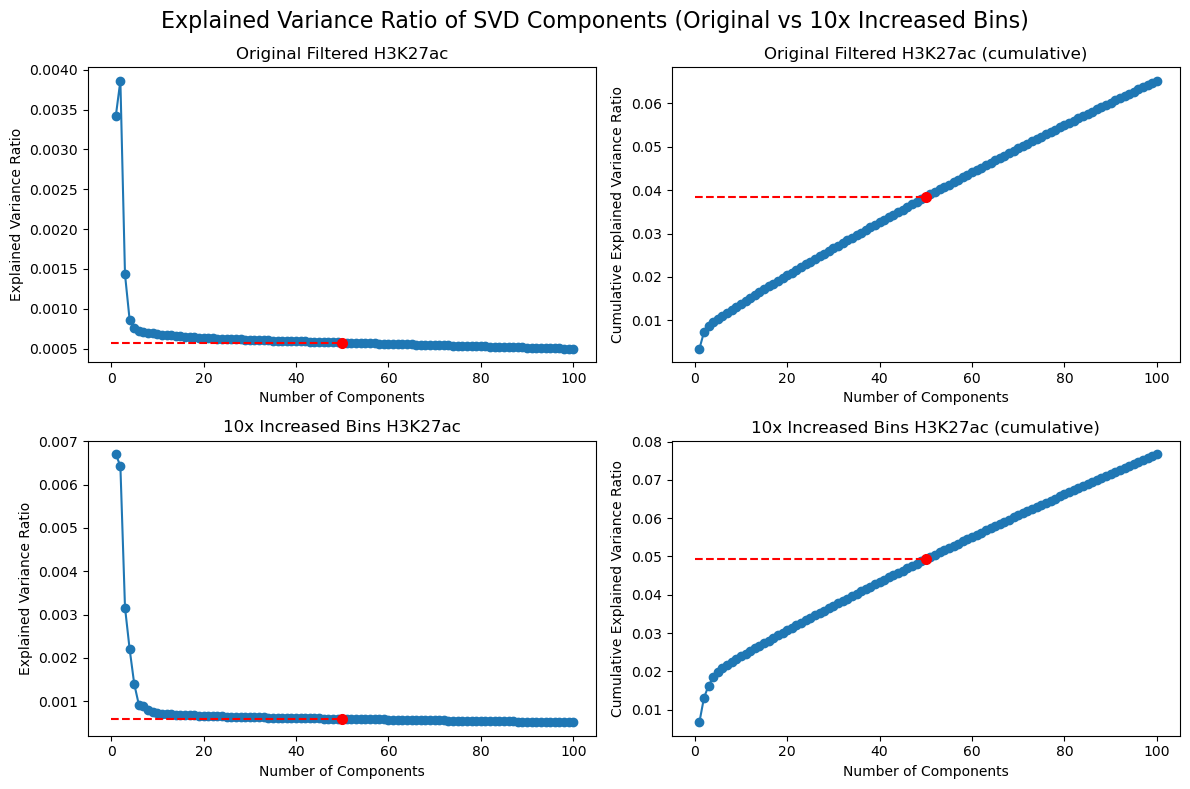

In [44]:
from sklearn.decomposition import TruncatedSVD
from matplotlib import pyplot as plt

#perform SVD on the tf-idf transformed data (filtered oginal and 10x)
svd = TruncatedSVD(n_components=100, random_state=42)
svd_H3K27ac = svd.fit_transform(tfidf_H3K27ac)
explain_var_H3K27ac = svd.explained_variance_ratio_
svd_10xH3K27ac = svd.fit_transform(tfidf_10xH3K27ac)
explain_var_10xH3K27ac = svd.explained_variance_ratio_

#Plot the elbow plot to visualize the explained variance ratio of the SVD components for both datasets
fig, ax = plt.subplots(2,2,figsize=(12, 8))
ax[0,0].plot(range(1, len(explain_var_H3K27ac) + 1), explain_var_H3K27ac, marker='o')
ax[0,0].set_title('Original Filtered H3K27ac')
ax[0,0].set_xlabel('Number of Components')
ax[0,0].set_ylabel('Explained Variance Ratio')
ax[0,0].plot(50, explain_var_H3K27ac[49], marker='o', markersize=7, color='red')
ax[0,0].hlines(y=explain_var_H3K27ac[49], xmin=0, xmax=50, color='red', linestyle='--')
ax[0,1].plot(range(1, len(explain_var_H3K27ac) + 1), np.cumsum(explain_var_H3K27ac), marker='o')
ax[0,1].set_title('Original Filtered H3K27ac (cumulative)')
ax[0,1].set_xlabel('Number of Components')
ax[0,1].set_ylabel('Cumulative Explained Variance Ratio')
ax[0,1].plot(50, np.sum(explain_var_H3K27ac[:50]), marker='o', markersize=7, color='red')
ax[0,1].hlines(y=np.sum(explain_var_H3K27ac[:50]), xmin=0, xmax=50, color='red', linestyle='--')
ax[1,0].plot(range(1, len(explain_var_10xH3K27ac) + 1), explain_var_10xH3K27ac, marker='o')
ax[1,0].set_title('10x Increased Bins H3K27ac')
ax[1,0].set_xlabel('Number of Components')
ax[1,0].set_ylabel('Explained Variance Ratio')
ax[1,0].plot(50, explain_var_10xH3K27ac[49], marker='o', markersize=7, color='red')
ax[1,0].hlines(y=explain_var_10xH3K27ac[49], xmin=0, xmax=50, color='red', linestyle='--')
ax[1,1].plot(range(1, len(explain_var_10xH3K27ac) + 1), np.cumsum(explain_var_10xH3K27ac), marker='o')
ax[1,1].set_title('10x Increased Bins H3K27ac (cumulative)')
ax[1,1].set_xlabel('Number of Components')
ax[1,1].set_ylabel('Cumulative Explained Variance Ratio')
ax[1,1].plot(50, np.sum(explain_var_10xH3K27ac[:50]), marker='o', markersize=7, color='red')
ax[1,1].hlines(y=np.sum(explain_var_10xH3K27ac[:50]), xmin=0, xmax=50, color='red', linestyle='--')
fig.suptitle('Explained Variance Ratio of SVD Components (Original vs 10x Increased Bins)', fontsize=16)
plt.tight_layout()
plt.show()

In [45]:
#first component can be technical and not biological -> direction of cells with high number of reads vs those with low number of reads
reads_per_cells = np.array(H3K27ac_filter.sum(axis=1)).flatten()
reads_per_cells_10x = np.array(filter_H3K27ac_10x.sum(axis=1)).flatten()
print(f'Correlation between first SVD component and number of reads per cell (original): {np.corrcoef(svd_H3K27ac[:, 0], reads_per_cells)[0, 1]}')
print(f'Correlation between first SVD component and number of reads per cell (10x): {np.corrcoef(svd_10xH3K27ac[:, 0], reads_per_cells_10x)[0, 1]}')

Correlation between first SVD component and number of reads per cell (original): 0.9991994712629985
Correlation between first SVD component and number of reads per cell (10x): 0.99721049529831


In [46]:
#highly correlated, so we need to remove it -> not help to find cell types
final_H3K27ac_svd = svd_H3K27ac[:, 1:51]  # Remove the first component and keep the 50 components that explain the most variance
final_10xH3K27ac_svd = svd_10xH3K27ac[:, 1:51]  

In [49]:
#normalize data
norm_H3K27ac = cpm_normalization(final_H3K27ac_svd)
norm_10xH3K27ac = cpm_normalization(final_10xH3K27ac_svd)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


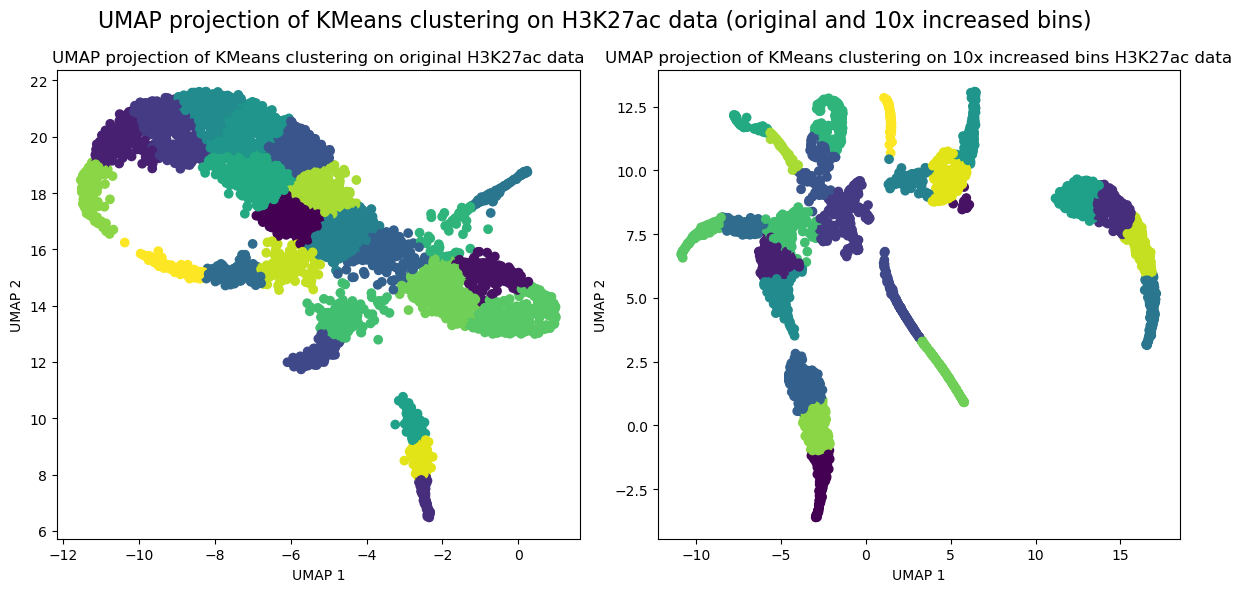

In [53]:
#clustering using KMeans
from sklearn.cluster import KMeans
import umap
from sklearn.preprocessing import LabelEncoder

nbre_type = len(np.unique(y))

#orignal H3K27ac data
emb_H3K27ac = umap.UMAP(n_neighbors=10, min_dist=0.3, random_state=42).fit_transform(norm_H3K27ac)
kmeans = KMeans(n_clusters=nbre_type, random_state=42)
labels_H3K27ac = kmeans.fit_predict(emb_H3K27ac)

#10x increased bins H3K27ac data
emb_10xH3K27ac = umap.UMAP(n_neighbors=10, min_dist=0.3, random_state=42).fit_transform(norm_10xH3K27ac)
kmeans = KMeans(n_clusters=nbre_type, random_state=42)
labels_10xH3K27ac = kmeans.fit_predict(emb_10xH3K27ac)

label_encoder = LabelEncoder()
label_encoder.fit(y)
y_encoded = label_encoder.transform(y)

fig, ax = plt.subplots(1, 2,figsize=(12, 6))
ax[0].scatter(emb_H3K27ac[:, 0], emb_H3K27ac[:, 1], c=labels_H3K27ac, cmap='viridis')
ax[0].set_title('UMAP projection of KMeans clustering on original H3K27ac data')
ax[0].set_xlabel('UMAP 1'); ax[0].set_ylabel('UMAP 2')

ax[1].scatter(emb_10xH3K27ac[:, 0], emb_10xH3K27ac[:, 1], c=labels_10xH3K27ac, cmap='viridis')
ax[1].set_title('UMAP projection of KMeans clustering on 10x increased bins H3K27ac data')
ax[1].set_xlabel('UMAP 1'); ax[1].set_ylabel('UMAP 2')

fig.suptitle('UMAP projection of KMeans clustering on H3K27ac data (original and 10x increased bins)', fontsize=16)
plt.tight_layout()
plt.show()

In [54]:
#control the clustering results with the cell types (ARI and NMI)
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

#calculate ARI and NMI for original H3K27ac data
ari_H3K27ac = adjusted_rand_score(y, labels_H3K27ac)
nmi_H3K27ac = normalized_mutual_info_score(y, labels_H3K27ac)

#calculate ARI and NMI for 10x increased bins H3K27ac data
ari_10xH3K27ac = adjusted_rand_score(y, labels_10xH3K27ac)
nmi_10xH3K27ac = normalized_mutual_info_score(y, labels_10xH3K27ac)

#print results
print('Original H3K27ac data:')
print(f' - ARI: {ari_H3K27ac:.3f} \n - NMI: {nmi_H3K27ac:.3f}')
print('10x increased bins H3K27ac data:')
print(f' - ARI: {ari_10xH3K27ac:.3f} \n - NMI: {nmi_10xH3K27ac:.3f}')

Original H3K27ac data:
 - ARI: 0.130 
 - NMI: 0.338
10x increased bins H3K27ac data:
 - ARI: 0.403 
 - NMI: 0.663


Number of non-null columns in 100x H3K27ac: 42440


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


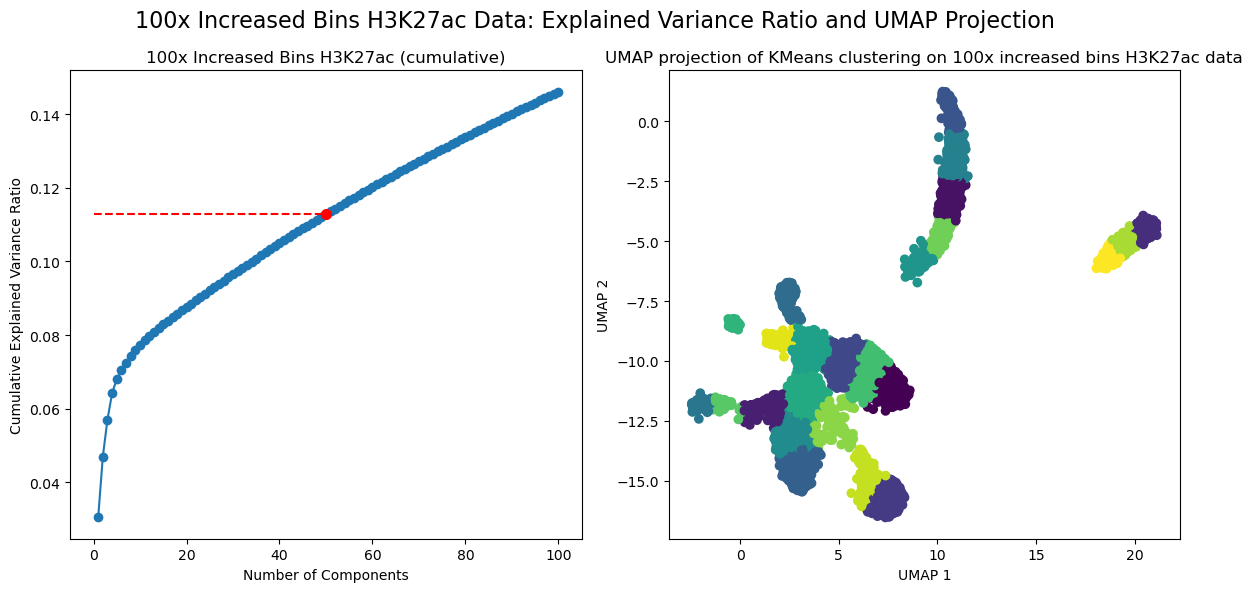

100x increased bins H3K27ac data:
 - ARI: 0.427 
 - NMI: 0.712


In [61]:
#increasing the bins size improves the clustering results, as shown by the higher ARI and NMI scores for the 10x increased bins H3K27ac data compared to the original H3K27ac data. This suggests that increasing the bin size helps to capture more relevant biological information and reduces noise in the data, leading to better clustering performance.

#testing a 100x increased bins H3K27ac data

#1) increase bins of H3K27ac for 100 times
H3K27ac_100x, ch_100x, st_100x, en_100x = increase_bins(data_H3K27ac, chrom_ac, start_ac, end_ac, factor=100)

#2) filter out the bins that have non-zero values in more than 50 cells
non_null_col_100x = H3K27ac_100x.getnnz(axis=0)
keep_100x = non_null_col_100x >= 50
print(f'Number of non-null columns in 100x H3K27ac: {keep_100x.sum()}')
filter_H3K27ac_100x = H3K27ac_100x[:, keep_100x]

#3) tf-idf transformation
tfidf_100xH3K27ac = tfidf_trans.fit_transform(filter_H3K27ac_100x)

#4) SVD
svd_100xH3K27ac = svd.fit_transform(tfidf_100xH3K27ac)
explain_var_100xH3K27ac = svd.explained_variance_ratio_

#5) remove the first component and keep the 50 components that explain the most variance
final_100xH3K27ac_svd = svd_100xH3K27ac[:, 1:51]

#6) normalize data
norm_100xH3K27ac = cpm_normalization(final_100xH3K27ac_svd)

#7) clustering using UMAP and KMeans
emb_100xH3K27ac = umap.UMAP(n_neighbors=70, min_dist=0.4, random_state=42).fit_transform(norm_100xH3K27ac)
labels_100xH3K27ac = kmeans.fit_predict(emb_100xH3K27ac)

#8) plot svd components and UMAP projection of KMeans clustering
fig, ax = plt.subplots(1, 2,figsize=(12, 6))

#plot the explained variance ratio of the SVD components
ax[0].plot(range(1, len(explain_var_100xH3K27ac) + 1), np.cumsum(explain_var_100xH3K27ac), marker='o')
ax[0].set_title('100x Increased Bins H3K27ac (cumulative)')
ax[0].set_xlabel('Number of Components')
ax[0].set_ylabel('Cumulative Explained Variance Ratio')
ax[0].plot(50, np.sum(explain_var_100xH3K27ac[:50]), marker='o', markersize=7, color='red')
ax[0].hlines(y=np.sum(explain_var_100xH3K27ac[:50]), xmin=0, xmax=50, color='red', linestyle='--')

#plot the UMAP projection of KMeans clustering
ax[1].scatter(emb_100xH3K27ac[:, 0], emb_100xH3K27ac[:, 1], c=labels_100xH3K27ac, cmap='viridis')
ax[1].set_title('UMAP projection of KMeans clustering on 100x increased bins H3K27ac data')
ax[1].set_xlabel('UMAP 1'); ax[1].set_ylabel('UMAP 2')

fig.suptitle('100x Increased Bins H3K27ac Data: Explained Variance Ratio and UMAP Projection', fontsize=16)
plt.tight_layout()
plt.show()

#9) control the clustering results with the cell types (ARI and NMI)
ari_100xH3K27ac = adjusted_rand_score(y, labels_100xH3K27ac)
nmi_100xH3K27ac = normalized_mutual_info_score(y, labels_100xH3K27ac)

print('100x increased bins H3K27ac data:')
print(f' - ARI: {ari_100xH3K27ac:.3f} \n - NMI: {nmi_100xH3K27ac:.3f}')